# **Trabalho Prático 1 - Análise Numérica**

Trabalho realizado pelos alunos do Grupo 19 no âmbito da unidade curricular de Análise Numérica (M2018) — 2024/2025:

Bruno	Manuel	Teixeira	Araújo Nº 202207580\
João Pereira Lobato Nº 202306182\
Pedro	Sebastião	Loureiro Pinto	Bessa Nº 202307026

---



# **Objetivos do Trabalho**

Neste trabalho, temos como objetivo dar uso aos conhecimentos acerca da propagação de erros no cálculo das somas de séries numéricas, determinando os tipos de critérios de convergência a usar para cada série, de forma a obter as somas finais com erros inferiores aos desejados.

São nos fornecidas duas fórmulas distintas para determinar aproximadamente o valor de π, com erro absoluto inferior a $ 1 \times 10^{-5} $, $ 1 \times 10^{-10} $ e $ 1 \times 10^{-15} $

Para tal, devemos criar algoritmos numa linguagem de escolha que nos permitam determinar tal aproximações, registando também o número de iterações realizadas e tendo em conta o epsilon máquina com que trabalhamos (o menor valor de diferença entre o 1 e o próximo número representável num sistema de vírgula flutuante).

Devemos registar e interpretar os resultados e também comentar e oferecer possíveis hipóteses que expliquem qualquer falha ou erro que possam ter surgido ao desenvolver e processar os nossos programas, que nos tenham impedido de chegar aos valores que desejariamos, quer a nível de programação mas principalmente a nível numérico, tendo em conta o nosso epsilon-máquina e a ordem de grandeza dos valores com os quais estamos a trabalhar.

# **Métodos a utilizar**

Para desenvolver os programas a utilizar neste trabalho, recorremos à linguagem Python, uma vez que era aquela com a qual todos os elementos do grupo estavam mais familiarizados, tendo esta sido lecionada em cadeiras anteriores da Licenciatura em Matemática, para além de ser efetivamente simples e de fácil compreensão e leitura.

Todos os cálculos relevantes foram feitos no caderno e depois passados para o trabalho utilizando um convertor de texto Latex, estando nestes presentes as razões que nos levaram a escolher cada critério de convergência das séries dadas e o número de iterações realizado pelo programas da série a) em função do valor de eps.


# **1 - Epsilon Máquina**
'Qual o valor de eps (epsilon máquina) com que vão trabalhar? Escrevam um programa que
permita calcular esse valor de eps:'


In [ ]:
# Calcular o epsilon da máquina

# Inicializar epsilon com 1.0
eps = 1.0

# Criar um ciclo para encontrar o menor epsilon onde 1.0 + eps é distinguível de 1.0
while (1.0 + eps) > 1.0:
    # Dividir epsilon por 2 em cada iteração para obter um número menor
    eps /= 2

# Multiplicar por 2 para obter o último epsilon que afetou a soma
eps *= 2

# Mostrar o resultado do epsilon da máquina
print("Epsilon da máquina calculado:", eps)


Epsilon da máquina calculado: 2.220446049250313e-16


O valor para epsilon-máquina(eps) obtido pelo programa está dado na base 2, uma vez que é também com potências de 2 com que a maior parte das linguagens de programação representam as vírgulas flutuantes, nomeadamente o Python, linguagem com a qual estamos a desenvolver este trabalho.

Para o escrever noutra base b, bastaria fazer a divisão por b em vez de 2 dentro do ciclo *while* e multiplicar eps por b em vez de 2 na penúltima linha do código.

# **2. a) - Cálculo de  π utilizando a fórmula de Leibniz**

Vamos calcular um valor aproximado de π com erro absoluto (majorado) inferior a um
valor ε dado, usando a fórmula de Leibniz.


A fórmula de Leibniz é dada por:

$$
\\π = 4∑_{n=0}^{\infty} \frac{(-1)^n}{2n + 1}
$$



Podemos facilmente ver, observando o numerador, que a fórmula contém uma série de termos alternadamente positivos e negativos. Verificaremos que é convergente:

$$
Seja\ a_n=\frac{(-1)^n}{2n + 1}
$$
Temos:
$$
\ 1)\lim_{x\to\infty} a_n = \frac{(-1)^n}{+\infty} = 0
$$


$$
Sabemos\ que\  a_{n+1}=\frac{(-1)^{n+1}}{2(n+1) + 1} = \frac{(-1)^{n+1}}{2n + 3}
$$

$$
Temos\   |2n+3|>|2n+1| ⟹ |\frac{1}{2n+3}| < |\frac{1}{2n+1}| ⟹ |\frac{(-1)^{n+1}}{2n+3}| < |\frac{(-1)^{n}}{2n+1}|
$$


$$
\ ∴ \   2)\ |a_{n+1}|<|a_n|
$$

$$
Por \ 1)\ e \ 2)\ podemos\ concluir\ que\ a_n\ é\ convergente.
$$

Assim, provada a convergência da série, basta criar um programa que calcule a soma de todos os termos da série até que o valor absoluto de um termo seja menor que ϵ, de forma a obter uma aproximação de π de acordo com o erro desejado.

In [ ]:
# Definir a função que implementa a fórmula de Leibniz
def formula_leibniz(epsilon):
    pi_approx = 0
    n = 0.0
    termo = 1                            # Iniciar com um valor maior que epsilon para iniciar o ciclo
    num=0
    # Ciclo para calcular a aproximação de π até que o valor absoluto de um termo seja menor que epsilon
    while abs(termo) >= epsilon:
      if n%2==0:                         # Verificar a partir da paridade do n qual o sinal que (-1)^n vai ter
        num=1
      else:
        num=-1
      termo = (num) / (2*n + 1)
      pi_approx += termo
      n += 1.0
    return 4.0 * pi_approx, n            # Retornar a aproximação de π e o número de iterações (n)

# Definir o valor de epsilon
epsilon = 1e-5                           # Pode ser qualquer valor desejado (a ser introduzido na função)


# Calcular o valor aproximado de π
valor_pi, iterations = formula_leibniz(epsilon)

# Exibir o resultado
print("Aproximação de π:", valor_pi)
print("Número de iterações:", iterations-1)


Aproximação de π: 3.141612653189785
Número de iterações: 50000.0


# **Resultados e possíveis justificações e hipóteses**


Foi possível calcular a aproximação de π com erro absoluto inferior a ϵ = $ 1 \times 10^{-5} $ rapidamente, assim como até ϵ = $ 1 \times 10^{-9} $, tal como era esperado. No entanto, o número de iterações realizadas no programa crescia rapidamente conforme o erro absoluto pedido, o que afetou drasticamente o tempo de execução do programa.


Como forma de ultrapassar este obstáculo, foi feita uma substituição no programa, susbtituindo o cálculo de $ (-1)^{n} $ dentro do ciclo (bloco de código que é repetido até verificar a condição pedida) por uma verificação do sinal desse termo de acordo com a paridade do n. Apesar de ser uma alteração simples, esta provocou uma grande melhoria no tempo de execução do programa, o que nos permitiu calcular também a aproximação de π com erro absoluto inferior a ϵ = $ 1 \times 10^{-10} $, como pedido. De forma a realçar o impacto que esta alteração no código teve no tempo de execução do programa, registamos esse mesmo tempo de execução do programa para cada ϵ=$ 1 \times 10^{i} $, com i∈{-5,-6,-7,-8,-9,-10}, na tabela 1. (ver abaixo)

É importante notar que estes tempos variam de um dispositivo para outro, de acordo com a quantidade de RAM alocado e que também variam no mesmo dispositivo de acordo com a qualidade da conexão com a Internet, pelo que é normal que ao executar novamente o programa os tempos registados sejam diferentes.

Nessa mesma tabela, foram também registados o número de casas decimais corretamente aproximadas por cada ϵ e também o número de iterações realizadas por cada programa, às quais nós determinamos uma fórmula  geral para calcular de acordo com o ϵ dado. ( ver Exemplo 1 e Generalização nºiterações )

Quanto ao erro absoluto inferior a ϵ=$ 1 \times 10^{-15} $, podemos concluir que, na prática, é muito difícil de calcular devido ao elevado número de iterações a realizar no programa (de acordo com as diferenças de tempo entre cada execução do programa para cada ϵ distinto levaria pelo menos mais de 10 dias a ser executado!), possivelmente devido à lenta convergência da série dada. Na teoria, como o epislon-máquina com o qual trabalhamos (na base 2, usada pelo Python) é menor do que o erro absoluto pedido, seria possível calcular a aproximação de π.

No entanto, como a convergência da série é muito lenta, são necessárias muitas iterações o que aumenta a acumulação de erros de arredondamento ao longo da soma, uma vez que são somados vários termos muito pequenos.


Podemos assim concluir que apesar da fórmula de Leibniz nos permitir calcular π com precisão razoável, tem um tempo de execução muito lento e que resulta num maior erro acumulado ao longo da soma comparada com outras fórmulas que possuam séries que possam convergir mais rapidamente.

# **Resultados Finais:**

Aproximação de π com erro absoluto inferior a ϵ = $ 1 \times 10^{-5} $ : 3.141612 ± $ 1 \times 10^{-5} $

Aproximação de π com erro absoluto inferior a ϵ = $ 1 \times 10^{-10} $ : 3.14159265378 ± $ 1 \times 10^{-10} $

Aproximação de π com erro absoluto inferior a ϵ = $ 1 \times 10^{-15} $ : *Não foi possível calcular em tempo razoável*

# **Tabela 1**
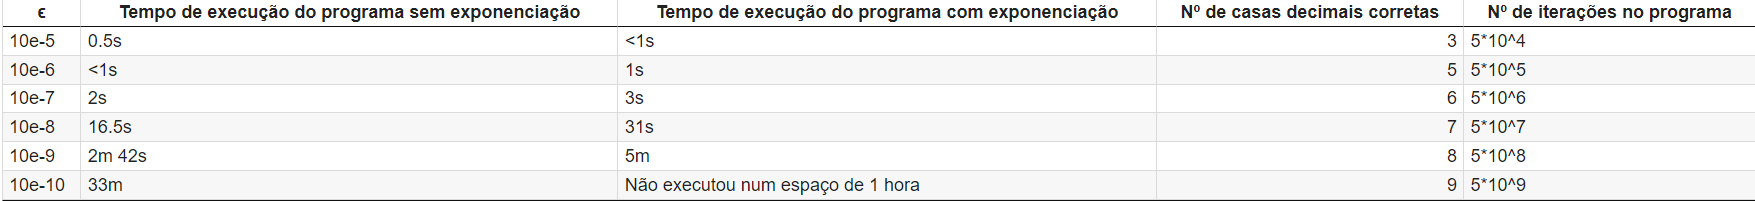

In [ ]:
from google.colab import data_table         #código usado para criar Tabela 1
import pandas as pd

data = {
    'ϵ': ['10e-5', '10e-6', '10e-7', '10e-8', '10e-9', '10e-10'],
    'Tempo de execução do programa sem exponenciação': ['0.5s', '<1s', '2s', '16.5s', '2m 42s', '33m'],
    'Tempo de execução do programa com exponenciação': ['<1s', '1s', '3s', '31s', '5m', 'Não executou num espaço de 1 hora'],
    'Nº de casas decimais corretas': [3, 5, 6, 7, 8, 9],
    'Nº de iterações no programa': ['5*10^4','5*10^5','5*10^6','5*10^7','5*10^8','5*10^9']
}
df = pd.DataFrame(data)
print('Tabela 1')
data_table.DataTable(df, include_index=False, num_rows_per_page=6)

Tabela 1


,ϵ,Tempo de execução do programa sem exponenciação,Tempo de execução do programa com exponenciação,Nº de casas decimais corretas,Nº de iterações no programa
0,10e-5,0.5s,<1s,3,5*10^4
1,10e-6,<1s,1s,5,5*10^5
2,10e-7,2s,3s,6,5*10^6
3,10e-8,16.5s,31s,7,5*10^7
4,10e-9,2m 42s,5m,8,5*10^8
5,10e-10,33m,Não executou num espaço de 1 hora,9,5*10^9


# Exemplo 1 e Generalização nºiterações
##**Exemplo 1**: Número de iterações desejadas pelo programa para eps= $1\times 10^{-10}$:


$$
\frac{|(-1)^n|}{|2n+1|} < 1 \times 10^{-10}
$$

$$
\frac{1}{2n+1} < 1 \times 10^{-10}
$$

$$
2n+1 > 10^{10}
$$

$$
2n > 10^{10} - 1
$$

$$
n > \frac{10^{10} -1}{2} = 4999999999.5
$$

Como n ∈ N , temos que :
$$
n = 5000000000 = 5\times10^{9}
$$




# **Por generalização, temos:**

$$
\frac{|(-1)^n|}{2n+1} < 1 \times 10^{k}  ,   k ∈ Z
$$

$$
n > \frac{10^{|k|} -1}{2} ⇒ n = 5\times10^{|k|-1} ,  n ∈ N
$$

$$
epsilon = 1 \times 10^{k}\ (caso\ geral)
$$

$$
Nº\ iterações = 5\times10^{|k|-1}
$$

# **2. b) - Cálculo de  π utilizando a fórmula  fórmula apresentada por Saha A. e Sinha A.**

Vamos calcular um valor aproximado de π utilizando a fórmula apresentada por Saha A. e Sinha A. (ver referência webgráfica 1).

A fórmula em causa é a seguinte:

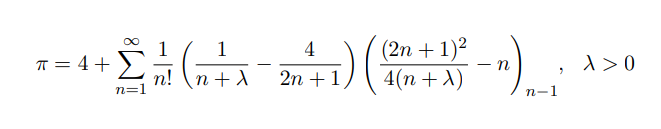

onde (x)n = x(x + 1)(x + 2)...(x + n − 1) é o símbolo de Pochhammer.


Iremos assumir que a série presente na fórmula é convergente sem prova concreta, devido à natureza desta nova fórmula e pelo facto de esta derivar de conceitos matemáticos que ainda não dominamos nem aprendemos neste curso.

Um facto curioso mas possívelmente relevante para este trabalho consiste no facto de esta fórmula, quando tomado λ->+∞, se tornar numa fórmula com uma série de termos alternados e que equivale à fórmula de Leibniz, utilizada em 2 a). Isto significa que na verdade a fórmula de Leibniz é apenas uma caso especial desta nova fórmula descoberta, mais geral (ver referência webgráfica 2 para prova desta equivalência).

No caso desta fórmula, foi feita uma estimativa do erro, devido à dificuldade de determinar o tipo de critério a utilizar para calcular o erro aproximado.

Iremos testar também a variação dos resultados conforme o valor de λ escolhido, para λ=10,50,100.

O programa criado para tal é o seguinte:

In [ ]:
#Definir a função para implementar a fórmula de Saha A. e Sinha A.
import math

def calculate_pi(lambdav, epsilon):    #função calcula aproximação de pi conforme o lambda e epsilon recebidos
    pi        = 4.0                    #inicialização da soma (já com o 4 somado com a série)
    n         = 1
    prev_pi   = 0.0                    #variável que guarda valor da soma anterior
    fatorial = n

    while abs(pi - prev_pi) >= epsilon:
        term1 = 1.0 / fatorial
        term2 = 1.0 / (n + lambdav) - 4.0 / (2*n + 1)
        term3 = ((2.0*n + 1.0)**2) / (4.0 * (n + lambdav)) - n

        pochhammer = 1.0
        for i in range(n-1):
            pochhammer *= (term3 + i)

        prev_pi = pi                  #guardar valor atual antes de fazer a sua soma(para fazer a verificação do ciclo)
        pi += term1 * term2 * pochhammer
        n += 1
        fatorial = fatorial * n       #usar o ciclo 'while' para definir a função fatorial

    return pi, n - 1

# Escolher parâmetros
lambdav = 50
epsilon = 1e-15



# Cálculo de pi
result, iterations = calculate_pi(lambdav, epsilon)

# Escrever os  resultados (valor aprox. de pi , número de iterações e erro absoluto)

formatted_value = f"{result:.16f}"                           #força o programa a apresentar o resultado com 16 casas decimais
print(f"Approximated value of pi: {formatted_value}")
print(f"Number of iterations:     {iterations}")
print(f"Difference from math.pi:  {abs(result - math.pi)}")  #módulo da diferença entre o valor aprox. e o valor exato (erro absoluto)
print(math.pi==result)                                       #verifica se o valor aproximado é considerado igual ao valor exato pelo Python

Approximated value of pi: 3.1415926535897940
Number of iterations:     38
Difference from math.pi:  8.881784197001252e-16
False


# **Resultados e possíveis justificações e hipóteses**

Foi possível calcular o valor aproximado de π com erro inferior a todos os valores pedidos, tendo-se verificado uma grande velocidade de execução nos programas e de eficácia dos mesmos.

De forma a apresentar os resultados, criamos as Tabelas 2, 3 e 4, com valores de λ=10, 50 e 100 respetivamente, onde registamos o tempo de execução dos programas, o número de dígitos corretos e o número de iterações para ϵ = $1 \times 10^{i}$ com i ∈ {-5,-6,-7,-8,-9,-10,-15}, de acordo com o valor de λ escolhido.

Verificamos que, ao comparar os valores obtidos com os registados na tabela 1, não só o programa foi muito mais rápido a obter o resultado pretendido (menor número de iterações e menor tempo de execução) como também nos permitiu calcular com a precisão pretendida o valor aproximado de π para ϵ = $1 \times 10^{-5}$, ϵ = $1 \times 10^{-10}$ e ϵ = $1 \times 10^{-15}$, ao contrário da fórmula de Leibniz.

Estes resultados demonstram que a série presente nesta fórmula converge muito mais rapidamente do que a série presente na fórmula de Leibniz, sendo assim mais eficaz para aproximar o valor de π com erro absoluto inferior a qualquer ϵ pretendido.

Isto provavelmente deve-se ao facto de o número de iterações ser tão pequeno, o que resulta numa contribuição quase mínima de erros de aproximação nas somas e multiplicações, sendo assim o erro acumulado nesta fórmula menor do que aquele verificado na fórmula de Leibniz.

Quanto ao valor de λ, as aproximações quando λ=50 e λ=100 foram as que continham um maior número de casas decimais corretas, o que indica que valores no intervalo [50,100] nos irão dar resultados mais precisos do que aqueles onde λ está em [1,49]. Isto não implica que quanto maior o valor de λ melhor a precisão, pois já referimos na introdução a este problema que está provado que quando λ tende para +∞, esta fórmula é equivalente á de Leibniz, a qual nos já concluimos ter uma menor eficácia e precisão do que esta mais recente.

Como para λ=50 foram necessárias menos iterações nos ciclos do que para λ=100, iremos apresentar os resultados finais com λ = 50, com o número de casas decimais adequado.

# **Resultados Finais:**


Para λ=50:

Aproximação de π com erro absoluto inferior a ϵ = $ 1 \times 10^{-5} $ : 3.141595  ± $ 1 \times 10^{-5} $

Aproximação de π com erro absoluto inferior a ϵ = $ 1 \times 10^{-10} $ : 3.14159265361  ± $ 1 \times 10^{-10} $

Aproximação de π com erro absoluto inferior a ϵ = $ 1 \times 10^{-15} $ : 3.1415926535897940 ± $ 1 \times 10^{-15} $


\
Observamos ainda que, para epsilon = 1e-16, o resultado de math.pi == result é **True**. Isso indica que a diferença entre o valor calculado e o valor exato de π é menor do que o épsilon da máquina, ou seja, tão pequena que o computador não a consegue detetar e representar.

Aproximação de π com erro absoluto inferior a ϵ = $ 1 \times 10^{-16} $ : 3.14159265358979312 ± $ 1 \times 10^{-16} $

# Tabela 2 : λ=10

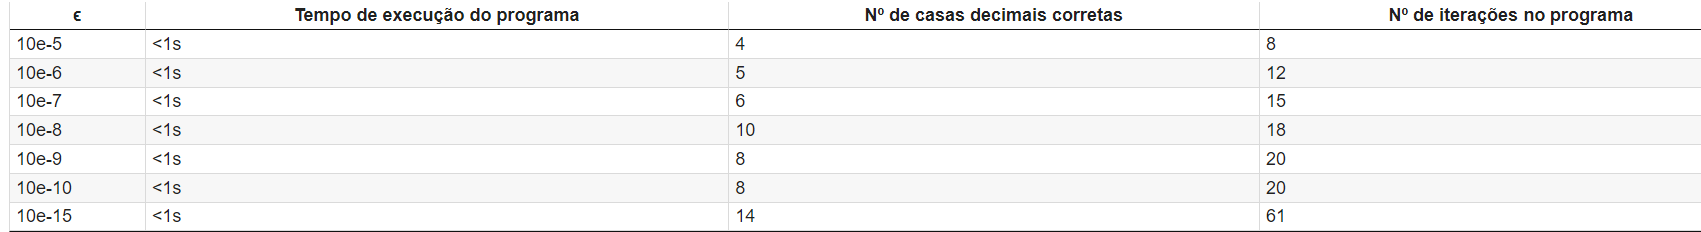

# Tabela 3 : λ=50

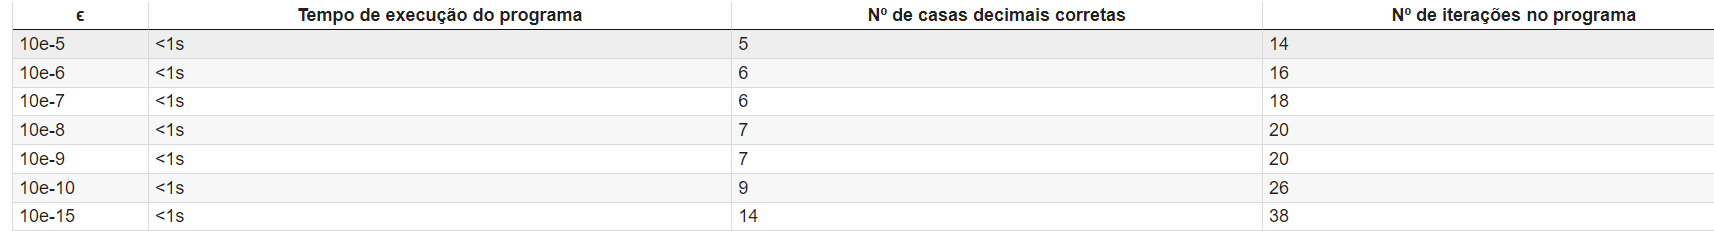

# Tabela 4: λ=100

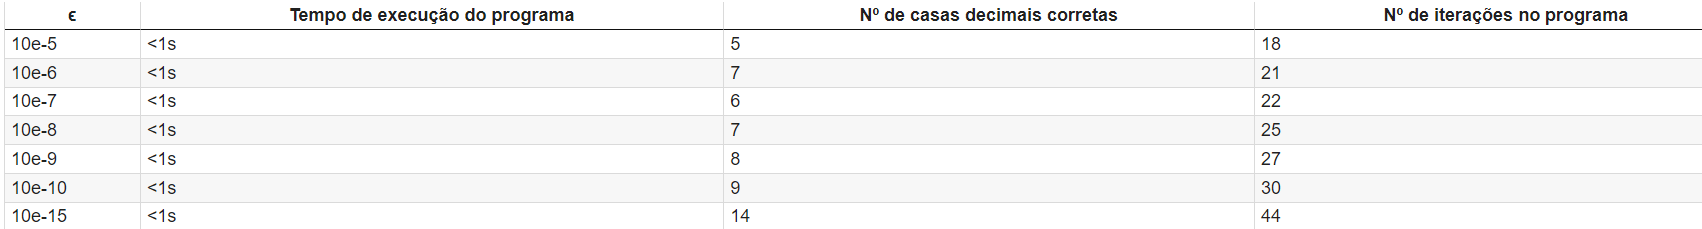

In [ ]:
from google.colab import data_table         #código usado para criar Tabela 2 (lambda=10)
import pandas as pd

data = {
    'ϵ': ['10e-5', '10e-6', '10e-7', '10e-8', '10e-9', '10e-10', '10e-15'],
    'Tempo de execução do programa ': ['<1s', '<1s', '<1s', '<1s', '<1s', '<1s', '<1s'],
    'Nº de casas decimais corretas': ['4', '5', '6', '10', '8', '8', '14'],
    'Nº de iterações no programa': ['8','12','15','18','20','20', '61']
}
df = pd.DataFrame(data)
print('Tabela 2 : lambda=10')
data_table.DataTable(df, include_index=False, num_rows_per_page=7)

Tabela 2 : lambda=10


,ϵ,Tempo de execução do programa,Nº de casas decimais corretas,Nº de iterações no programa
0,10e-5,<1s,4,8
1,10e-6,<1s,5,12
2,10e-7,<1s,6,15
3,10e-8,<1s,10,18
4,10e-9,<1s,8,20
5,10e-10,<1s,8,20
6,10e-15,<1s,14,61


In [ ]:
from google.colab import data_table         #código usado para criar Tabela 3 (lambda=50)
import pandas as pd

data = {
    'ϵ': ['10e-5', '10e-6', '10e-7', '10e-8', '10e-9', '10e-10', '10e-15'],
    'Tempo de execução do programa ': ['<1s', '<1s', '<1s', '<1s', '<1s', '<1s', '<1s'],
    'Nº de casas decimais corretas': ['5', '6', '6', '7', '7', '9', '14'],
    'Nº de iterações no programa': ['14','16','18','20','20','26', '38']
}
df = pd.DataFrame(data)
print('Tabela 3 : lambda=50')
data_table.DataTable(df, include_index=False, num_rows_per_page=7)

Tabela 3 : lambda=50


,ϵ,Tempo de execução do programa,Nº de casas decimais corretas,Nº de iterações no programa
0,10e-5,<1s,5,14
1,10e-6,<1s,6,16
2,10e-7,<1s,6,18
3,10e-8,<1s,7,20
4,10e-9,<1s,7,20
5,10e-10,<1s,9,26
6,10e-15,<1s,14,38


In [ ]:
from google.colab import data_table         #código usado para criar Tabela 4 (lambda=100)
import pandas as pd

data = {
    'ϵ': ['10e-5', '10e-6', '10e-7', '10e-8', '10e-9', '10e-10', '10e-15'],
    'Tempo de execução do programa ': ['<1s', '<1s', '<1s', '<1s', '<1s', '<1s', '<1s'],
    'Nº de casas decimais corretas': ['5', '7', '6', '7', '8', '9', '14'],
    'Nº de iterações no programa': ['18','21','22','25','27','30', '44']
}
df = pd.DataFrame(data)
print('Tabela 4 : lambda=100')
data_table.DataTable(df, include_index=False, num_rows_per_page=7)

Tabela 4 : lambda=100


,ϵ,Tempo de execução do programa,Nº de casas decimais corretas,Nº de iterações no programa
0,10e-5,<1s,5,18
1,10e-6,<1s,7,21
2,10e-7,<1s,6,22
3,10e-8,<1s,7,25
4,10e-9,<1s,8,27
5,10e-10,<1s,9,30
6,10e-15,<1s,14,44


Referências Webgráficas:

1) https://journals.aps.org/prl/abstract/10.1103/PhysRevLett.132.221601

2)https://www.scientificamerican.com/article/string-theorists-accidentally-find-a-new-formula-for-pi/